In [1]:
import matplotlib.pyplot as plt
import numpy as np

from superfv.tools.rk_stability import ssprk3_amplification, plot_stability_region, compute_fv_upwinding_rk_amplification, cfl
from superfv.tools.fv_advection_stability import plot_fv_upwind_Omega_h_over_a_harmonic_trace, theta

In [2]:
def plot_rk3_stability(ax, n=100, **kwargs):
    x, y = np.meshgrid(np.linspace(-5,1,n), np.linspace(-3,3,n))
    z = x + 1j*y
    pp = np.abs(1+z+z**2/2+z**3/6) # RK3 amplification factor
    ax.contour(x, y, pp, **kwargs)

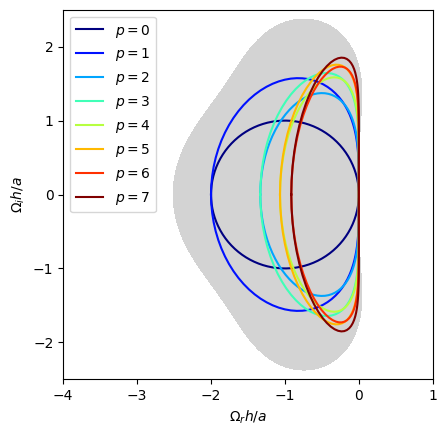

In [3]:
xlim = -4, 1
ylim = -2.5, 2.5
nmesh = 256

fig, ax = plt.subplots()
ax.set_xlabel(r"$\Omega_r h / a$")
ax.set_ylabel(r"$\Omega_i h / a$")
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal')

# ASSUMES CFL=1.0
plot_stability_region(ax, ssprk3_amplification, np.linspace(xlim[0], xlim[1], nmesh), np.linspace(ylim[0], ylim[1], nmesh), levels=[0.0, 1.0], colors="lightgrey", fill=True)

for p in range(8):
    plot_fv_upwind_Omega_h_over_a_harmonic_trace(ax, p, color=plt.cm.jet(p / 7), label=fr"$p={p}$")

ax.legend()

In [4]:
amplification = compute_fv_upwinding_rk_amplification(3)
amplification

sqrt(2565726409*CFL**6*sin(1.0*theta)**6/6879707136 - 69343957*CFL**6*sin(1.0*theta)**5*sin(2.0*theta)/143327232 + 69343957*CFL**6*sin(1.0*theta)**5*sin(3.0*theta)/1146617856 + 9370805*CFL**6*sin(1.0*theta)**4*sin(2.0*theta)**2/35831808 - 9370805*CFL**6*sin(1.0*theta)**4*sin(2.0*theta)*sin(3.0*theta)/143327232 + 9370805*CFL**6*sin(1.0*theta)**4*sin(3.0*theta)**2/2293235712 + 46854025*CFL**6*sin(1.0*theta)**4*cos(1.0*theta)**2/254803968 - 9370805*CFL**6*sin(1.0*theta)**4*cos(1.0*theta)*cos(2.0*theta)/63700992 + 9370805*CFL**6*sin(1.0*theta)**4*cos(1.0*theta)*cos(3.0*theta)/382205952 - 46854025*CFL**6*sin(1.0*theta)**4*cos(1.0*theta)/191102976 + 1874161*CFL**6*sin(1.0*theta)**4*cos(2.0*theta)**2/63700992 - 1874161*CFL**6*sin(1.0*theta)**4*cos(2.0*theta)*cos(3.0*theta)/191102976 + 9370805*CFL**6*sin(1.0*theta)**4*cos(2.0*theta)/95551488 + 1874161*CFL**6*sin(1.0*theta)**4*cos(3.0*theta)**2/2293235712 - 9370805*CFL**6*sin(1.0*theta)**4*cos(3.0*theta)/573308928 + 46854025*CFL**6*sin(1.0*thet

In [5]:
thetas = [0.0, np.pi / 2, np.pi, 3 * np.pi / 2]
CFLs = np.linspace(0.4, 1.8, 15)

max_amps = []
for CFL_value in CFLs:
    amplification_at_cfl = amplification.subs(cfl, CFL_value)
    max_amp = 0
    for theta_value in thetas:
        amp = float(amplification_at_cfl.subs(theta, theta_value))
        max_amp = max(max_amp, amp)
    max_amps.append(max_amp)

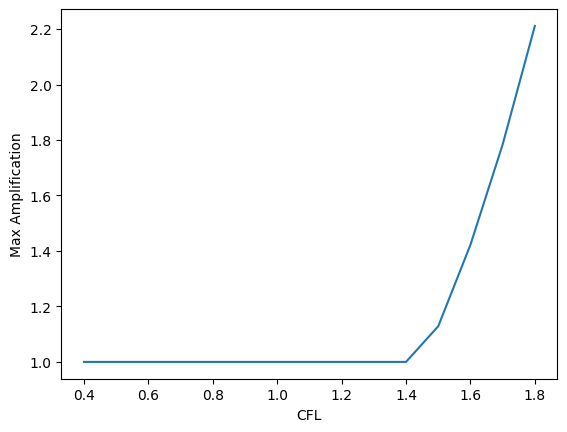

In [6]:
fig, ax = plt.subplots()
ax.set_xlabel('CFL')
ax.set_ylabel('Max Amplification')

ax.plot(CFLs, max_amps)